# QE008: The Quantum Relay Attack

**Three small quantum games from cryptography: proving you are close, counting votes privately, and hiding in noise.**

Modern security is not only about secret messages. It is also about *who* you are talking to, *where* they are,
and *how much* a computation reveals. This exercise looks at three such questions with a quantum twist:

* **Part A: privacy-preserving authentication (one exact answer, Euler-style).** A car unlocks when its key is close
  by. Thieves defeat this with a *relay attack*: one thief stands next to the car, another next to the owner's key, and
  they forward the signals. *Distance bounding* stops this by timing very fast challenge–response rounds: the key must
  answer faster than any signal could travel to a far-away accomplice and back. We send the challenges as **qubits** and
  compute, exactly, the best a quantum attacker can do.
* **Part B1: fixing the protocol.** One extra secret bit closes the hole, and quantum challenges then beat the classical
  protocol against a dishonest key holder.
* **Part B2: secure multi-party computation.** Five people count yes/no votes with an entangled state, so that only
  the total is revealed.
* **Part B3: a privacy-enhancing technology.** Hardware noise, usually the enemy, turns into a formal *differential
  privacy* guarantee for that total.

### Words used in this notebook

| term | meaning |
|---|---|
| **verifier / prover** | the verifier (the car, a door) checks a claim; the prover (the key, a phone) tries to prove it is genuine and close |
| **protocol** | the fixed list of messages two parties exchange |
| **shared key** | secret bits the genuine prover and verifier both know in advance |
| **round** | one fast challenge → response exchange; a protocol uses many rounds |
| **relay / mafia fraud** | an outside attacker, near the verifier, tries to pass rounds while the genuine prover is far away |
| **pre-ask** | the attacker's trick: before the round, query the far-away prover to learn something useful |
| **distance fraud** | the genuine but *dishonest* prover is far away and answers early, before the challenge reaches it |
| **qubit** | the quantum version of a bit; its state is an arrow on a circle (here: real amplitudes only) |
| **basis** | a pair of perpendicular directions a qubit can be measured along. **Z basis** = 0° / 90° (states \|0⟩, \|1⟩); **X basis** = 45° / 135° (states \|+⟩, \|−⟩) |
| **BB84 states** | the four states \|0⟩, \|1⟩, \|+⟩, \|−⟩. Measuring in the wrong basis gives a random result |
| **Helstrom measurement** | the best possible single measurement to tell two quantum states apart |
| **SDP (semidefinite program)** | an optimisation problem a computer can solve *exactly* to many digits. Here it finds the best attack over *all* strategies quantum mechanics allows |
| **see-saw** | a search that alternately improves the attacker's sent state and its measurement; it finds an actual attack, which the SDP then proves is the best |
| **entanglement / GHZ state** | qubits (or qudits) linked so they behave as one object. A GHZ state is the simplest many-party version |
| **qudit** | like a qubit but with *d* levels instead of 2 |
| **secure multi-party computation (MPC)** | several parties compute a function of their private inputs (e.g. a vote total) and learn nothing except the result |
| **differential privacy (ε)** | a promise that one person changing their input changes the probability of any published result by at most a factor $e^{\varepsilon}$. Smaller ε = more privacy |
| **random seed** | fixes the random draws so every run gives the same numbers |

This notebook needs `numpy`, `scipy`, `matplotlib`, `pandas` and `cvxpy` (`pip install cvxpy`). It runs in about a minute.

In [1]:
import itertools as it
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.stats import binom
try:
    import cvxpy as cp
except ImportError:
    raise ImportError("This notebook needs cvxpy for the exact attack bound:  pip install cvxpy")

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
BLUE, ORANGE, GREEN, GRAY, INK = "#2a78d6", "#eb6834", "#1f9e6e", "#8a8984", "#0b0b0b"
rng = np.random.default_rng(8)                                   # random seed

ket = lambda angle: np.array([np.cos(angle), np.sin(angle)])     # qubit state as an arrow at this angle
proj = lambda v: np.outer(v, v)                                  # |v><v|
BASIS = {"Z": [ket(0), ket(np.pi / 2)],                          # |0>, |1>
         "X": [ket(np.pi / 4), ket(3 * np.pi / 4)]}              # |+>, |->
bit = lambda b: proj(BASIS["Z"][b])                              # a classical bit written as a qubit

## Part A: the naive quantum distance-bounding round

**One fast round of the protocol:**

1. The prover and verifier share a secret basis $\theta \in \{Z, X\}$ for this round (taken from their shared key).
2. The verifier picks a random challenge bit $c$, encodes it as the qubit $|c\rangle_\theta$ (one of the BB84 states)
   and starts a clock.
3. The genuine prover knows $\theta$, measures in that basis, gets $c$ exactly and sends it back.
4. The verifier accepts the round if the answer is $c$ and arrived fast enough.

**The attacker** sits right next to the verifier. Being close, it is fast enough. But it does not know $\theta$, and the
genuine prover is too far away to ask *during* the round. Before the round it may **pre-ask**: send the prover any
qubit it likes and receive the prover's answer, which is the prover's measurement of that qubit in basis $\theta$.
That answer leaks information about the secret basis.

**Task.** Let $p^\ast$ be the highest probability, over *every* attack allowed by quantum mechanics, that the attacker
passes one round. Report

$$A = \lfloor 10^6 \cdot p^\ast \rfloor .$$

*Check value:* an attacker who skips the pre-ask and just measures the verifier's qubit as well as possible (Helstrom)
passes with $\tfrac12 + \tfrac{\sqrt2}{4} = 0.853553\ldots$, which would give 853553.

In [2]:
# attack without pre-ask: tell apart "c = 0" = mix of |0>,|+>  from  "c = 1" = mix of |1>,|->
rho = [0.5 * (proj(BASIS["Z"][c]) + proj(BASIS["X"][c])) for c in (0, 1)]
p_no_preask = 0.5 + 0.25 * np.abs(np.linalg.eigvalsh(rho[0] - rho[1])).sum()   # Helstrom formula
print(f"check value, no pre-ask: {p_no_preask:.9f}  ->  {int(1e6 * p_no_preask)}")

check value, no pre-ask: 0.853553391  ->  853553


### Finding the best attack: an exact SDP

The attacker acts twice: first it sends a qubit **Q** to the prover, then it receives the prover's answer **R** and the
verifier's challenge qubit **V**, and outputs a guess **G**. It may keep any quantum memory in between. Every such
two-step strategy can be written as one positive matrix $C$ on the four systems Q, R, V, G (its *Choi matrix*, a
"quantum comb") obeying one causality condition: what happens before R and V arrive cannot depend on them:

$$C \succeq 0, \qquad \operatorname{Tr}_G\, C = \rho_Q \otimes I_{RV}, \qquad \operatorname{Tr}\rho_Q = 1 .$$

The protocol is also a matrix $T$ (the prover's measurement, the verifier's qubit and the winning condition, averaged
over the secret basis and the challenge). The attacker's success probability is $\operatorname{Tr}(C\,T)$. Maximising
a linear function over positive matrices is an SDP. Its answer covers every attack: any memory size, entanglement,
any measurement.

The same code also handles two variants used later: a **response key** (the prover answers $c \oplus k$ with a second
secret bit $k$), and the **classical** protocol of Hancke and Kuhn (challenges are ordinary bits; the prover answers
from two secret response registers).

In [3]:
def protocol_matrix(kind):
    # T on systems Q (attacker's pre-ask qubit), R (prover's reply), V (verifier's challenge), G (attacker's guess)
    T = np.zeros((16, 16))
    if kind in ("naive quantum", "quantum + response key"):
        keys = (0, 1) if kind == "quantum + response key" else (0,)
        for th, k, c in it.product("ZX", keys, (0, 1)):
            weight = 1 / (2 * len(keys) * 2)
            prover = sum(np.kron(proj(BASIS[th][m]), bit(m ^ k)) for m in (0, 1))   # measure in th, reply m xor k
            T += weight * np.kron(np.kron(prover, proj(BASIS[th][c])), bit(c ^ k))
    elif kind == "classical (Hancke-Kuhn)":
        for R0, R1, c in it.product((0, 1), (0, 1), (0, 1)):                        # two secret response registers
            reg = (R0, R1)
            prover = sum(np.kron(bit(q), bit(reg[q])) for q in (0, 1))               # pre-ask q -> reply R_q
            T += (1 / 8) * np.kron(np.kron(prover, bit(c)), bit(reg[c]))
    return T

def best_attack(T):
    Cm = cp.Variable((16, 16), symmetric=True)
    rho_Q = cp.Variable((2, 2), symmetric=True)
    constraints = [Cm >> 0, rho_Q >> 0, cp.trace(rho_Q) == 1,
                   cp.partial_trace(Cm, [2, 2, 2, 2], axis=3) == cp.kron(rho_Q, np.eye(4))]
    problem = cp.Problem(cp.Maximize(cp.trace(Cm @ T)), constraints)
    problem.solve(solver=cp.CLARABEL)
    return problem.value

p_star = best_attack(protocol_matrix("naive quantum"))
A = int(np.floor(1e6 * p_star))
print(f"best attack on the naive protocol: p* = {p_star:.9f}")
print(f"closed form (2 + sqrt 3)/4       :      {(2 + np.sqrt(3)) / 4:.9f}")
print(f"\nANSWER  A = {A}")

best attack on the naive protocol: p* = 0.933012701
closed form (2 + sqrt 3)/4       :      0.933012702

ANSWER  A = 933012


### What does the best attack look like?

The SDP gives an upper limit. To show the limit is actually *reached*, search directly over a simple family of attacks:
send the prover a qubit at angle φ, read its reply r, then make the best measurement of the verifier's qubit given r.

send a qubit at 67.50 degrees  ->  success 0.933012702
then measure the challenge along 40.1 deg if the prover said 0, 4.9 deg if it said 1


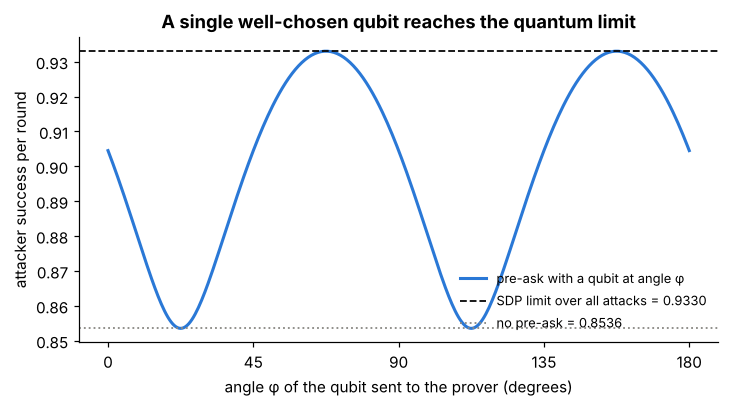

In [4]:
def attack_success(phi, return_readout=False):
    sent = ket(phi)
    total, readout = 0.0, {}
    for r in (0, 1):
        # weight of each (basis, challenge) given the prover replied r
        O = [sum(0.25 * (BASIS[th][r] @ sent) ** 2 * proj(BASIS[th][c]) for th in "ZX") for c in (0, 1)]
        ev, U = np.linalg.eigh(O[0] - O[1])
        total += np.trace(O[1]) + ev[ev > 0].sum()
        readout[r] = np.degrees(np.arctan2(U[1, -1], U[0, -1])) % 180     # direction that means "guess 0"
    return (total, readout) if return_readout else total

opt = minimize_scalar(lambda a: -attack_success(a), bounds=(0, np.pi / 2), method="bounded")
phi_star = opt.x
p_explicit, readout = attack_success(phi_star, True)
print(f"send a qubit at {np.degrees(phi_star):.2f} degrees  ->  success {p_explicit:.9f}")
print(f"then measure the challenge along {readout[0]:.1f} deg if the prover said 0, "
      f"{readout[1]:.1f} deg if it said 1")

angles = np.linspace(0, np.pi, 361)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(np.degrees(angles), [attack_success(a) for a in angles], color=BLUE, lw=2, label="pre-ask with a qubit at angle φ")
ax.axhline(p_star, color=INK, lw=1.2, ls="--", label=f"SDP limit over all attacks = {p_star:.4f}")
ax.axhline(p_no_preask, color=GRAY, lw=1.2, ls=":", label=f"no pre-ask = {p_no_preask:.4f}")
ax.set_xlabel("angle φ of the qubit sent to the prover (degrees)"); ax.set_ylabel("attacker success per round")
ax.set_xticks(range(0, 181, 45)); ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax.set_title("A single well-chosen qubit reaches the quantum limit"); plt.show()

At φ = 67.5° the explicit attack reaches the SDP limit, so $p^\ast = (2+\sqrt3)/4$ is achieved. No entanglement and no
quantum memory are needed: one tilted qubit sent to the prover leaks enough about the secret basis.

**Monte Carlo check.** Simulate 200,000 rounds of this attack, with real random draws.

In [5]:
def simulate_attack(n_rounds, phi, readout):
    th = rng.integers(2, size=n_rounds)                                  # secret basis: 0 = Z, 1 = X
    c = rng.integers(2, size=n_rounds)                                   # challenge bit
    basis_angle = np.where(th == 0, 0.0, np.pi / 4)                      # direction of |0>_theta
    r = (rng.random(n_rounds) > np.cos(phi - basis_angle) ** 2).astype(int)        # prover measures attacker's qubit
    challenge_angle = basis_angle + c * np.pi / 2                        # direction of |c>_theta
    look = np.radians(np.where(r == 0, readout[0], readout[1]))          # attacker's measurement direction
    guess = (rng.random(n_rounds) > np.cos(look - challenge_angle) ** 2).astype(int)
    return (guess == c).mean()

n_mc = 200_000
rate = simulate_attack(n_mc, phi_star, readout)
print(f"simulated success: {rate:.4f} ± {np.sqrt(rate * (1 - rate) / n_mc):.4f}   (exact {p_star:.4f})")

simulated success: 0.9329 ± 0.0006   (exact 0.9330)


## Part B1: fixing the protocol

The leak exists because the prover's reply to the pre-ask *is* a measurement in the secret basis. The fix: the prover
replies $c \oplus k$, where $k$ is a second secret bit per round. A pre-ask reply now looks random to the attacker.
The same SDP gives the new limit, and also the classical Hancke–Kuhn protocol for comparison.

**Distance fraud** (a dishonest prover far away, answering before the challenge arrives) needs no SDP:

* classical: the prover knows both response registers $R_0, R_1$; when they agree (half the time) it is always right,
  otherwise it guesses: $\tfrac12 + \tfrac12\cdot\tfrac12 = \tfrac34$;
* quantum: the reply depends on $c$, which travels inside a qubit that has not arrived yet, so it can only guess: $\tfrac12$.

In [6]:
mafia = {k: best_attack(protocol_matrix(k)) for k in ["classical (Hancke-Kuhn)", "naive quantum", "quantum + response key"]}
distance = {"classical (Hancke-Kuhn)": 0.75, "naive quantum": 0.5, "quantum + response key": 0.5}
table = pd.DataFrame({"relay attack (mafia fraud)": mafia, "dishonest prover (distance fraud)": distance}).round(6)
table.index.name = "protocol, best attack per round"
table

,relay attack (mafia fraud),dishonest prover (distance fraud)
"protocol, best attack per round",,
classical (Hancke-Kuhn),0.750000,0.75
naive quantum,0.933013,0.50
quantum + response key,0.750000,0.50


**How many rounds?** A real protocol runs $n$ rounds and accepts if at least $\tau$ answers are right. Noise means even
the genuine prover gets a fraction $e$ of rounds wrong. We want both:

* attacker accepted with probability ≤ $10^{-6}$ (false accept), and
* genuine prover rejected with probability ≤ $10^{-3}$ (false reject).

For every protocol and noise level, find the smallest $n$ (and its threshold $\tau$) that meets both targets.

In [7]:
def rounds_needed(q_attack, e_noise, fa=1e-6, fr=1e-3, n_max=3000):
    for n in range(1, n_max + 1):
        tau = np.arange(n + 1)
        false_accept = binom.sf(tau - 1, n, q_attack)          # attacker gets >= tau right
        false_reject = binom.cdf(tau - 1, n, 1 - e_noise)      # genuine prover gets < tau right
        if np.any((false_accept <= fa) & (false_reject <= fr)):
            return n
    return np.nan

noise = [0.0, 0.02, 0.05, 0.10]
cases = {"classical: relay attack": 0.75, "classical: dishonest prover": 0.75,
         "naive quantum: relay attack": table.loc["naive quantum", "relay attack (mafia fraud)"],
         "quantum + key: relay attack": table.loc["quantum + response key", "relay attack (mafia fraud)"],
         "quantum + key: dishonest prover": 0.5}
def describe(q, e):
    if 1 - e <= q:
        return "impossible"                                    # attacker as good as the genuine prover
    n = rounds_needed(q, e)
    return "> 3000" if np.isnan(n) else str(n)

rounds = pd.DataFrame({name: [describe(q, e) for e in noise] for name, q in cases.items()},
                      index=[f"noise {int(100 * e)}%" for e in noise]).T
rounds.index.name = "rounds needed"
rounds

,noise 0%,noise 2%,noise 5%,noise 10%
rounds needed,,,,
classical: relay attack,49,112,180,388
classical: dishonest prover,49,112,180,388
naive quantum: relay attack,200,1118,> 3000,impossible
quantum + key: relay attack,49,112,180,388
quantum + key: dishonest prover,20,36,49,73


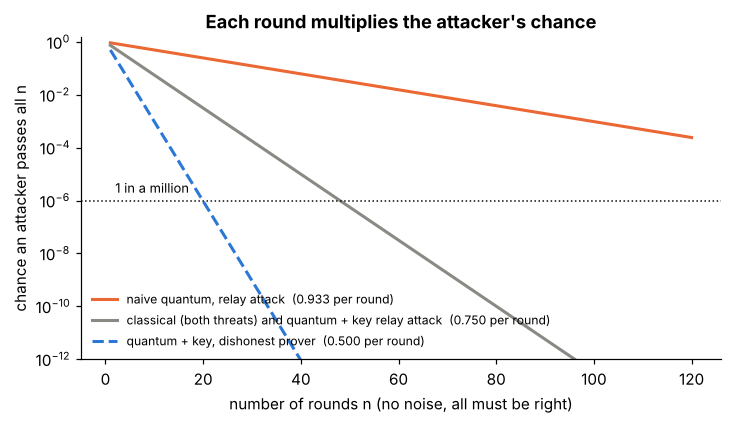

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
nn = np.arange(1, 121)
for q, col, ls, lab in [(cases["naive quantum: relay attack"], ORANGE, "-", "naive quantum, relay attack"),
                        (0.75, GRAY, "-", "classical (both threats) and quantum + key relay attack"),
                        (0.5, BLUE, "--", "quantum + key, dishonest prover")]:
    ax.semilogy(nn, q ** nn, color=col, lw=2, ls=ls, label=f"{lab}  ({q:.3f} per round)")
ax.axhline(1e-6, color=INK, lw=1, ls=":"); ax.text(2, 2e-6, "1 in a million", fontsize=8.5)
ax.set_xlabel("number of rounds n (no noise, all must be right)"); ax.set_ylabel("chance an attacker passes all n")
ax.set_ylim(1e-12, 1.5); ax.legend(frameon=False, fontsize=8, loc="lower left")
ax.set_title("Each round multiplies the attacker's chance"); plt.show()

The naive quantum protocol needs four times as many rounds as the classical one on a perfect channel, ten times as
many at 2% noise, and stops working entirely at 10% noise, where the relay attacker (93% per round) is better than
the genuine prover (90%). With the response key, relay resistance equals the classical protocol (both 3/4), and
protection against a dishonest prover needs 2.5 to 5 times fewer rounds (1/2 instead of 3/4 per round).

## Part B2: counting votes without revealing them (secure multi-party computation)

Five people vote yes (1) or no (0). They want the **total** but no one, including everyone else together, should learn
an individual vote from the published data.

**Quantum protocol.** A source hands each voter one part of a **GHZ state** of qudits with $d = 6$ levels
(enough to hold totals 0–5):

$$|\mathrm{GHZ}\rangle = \tfrac{1}{\sqrt d}\sum_{j=0}^{d-1} |j\,j\,j\,j\,j\rangle .$$

1. Voter $i$ with vote $x_i$ applies a phase $|j\rangle \to \omega^{j x_i}|j\rangle$, with $\omega = e^{2\pi i/d}$.
   Phases from all voters add up in one shared phase, $\omega^{j S}$ with $S = \sum_i x_i$.
2. Each voter measures in the Fourier basis (the qudit version of the X basis) and **publicly announces** the outcome $b_i$.
3. The total is $S = \sum_i b_i \bmod d$.

The announced numbers are uniformly random apart from their sum, so the published data reveals the total and
nothing else. Below we simulate the full $6^5 = 7{,}776$-dimensional quantum state.

In [9]:
N_VOTERS, D = 5, 6

def announced_distribution(votes, phase_error=0):
    # exact probability of every list of announcements (b_1..b_5); phase_error shifts one voter's qudit
    j = np.arange(D)
    psi = np.zeros((D,) * N_VOTERS, complex)
    for jj in j:
        psi[(jj,) * N_VOTERS] = 1 / np.sqrt(D)
    for i, x in enumerate(list(votes)):
        shape = [1] * N_VOTERS; shape[i] = D
        psi = psi * np.exp(2j * np.pi * j * (x + (phase_error if i == 0 else 0)) / D).reshape(shape)
    for axis in range(N_VOTERS):                                  # Fourier-basis measurement on every qudit
        psi = np.fft.fft(psi, axis=axis, norm="ortho")
    return np.abs(psi) ** 2

def run_vote(votes, n_runs=2000):
    P = announced_distribution(votes).ravel()
    outcomes = rng.choice(P.size, n_runs, p=P)
    b = np.array(np.unravel_index(outcomes, (D,) * N_VOTERS)).T
    return b, b.sum(1) % D                                       # total = sum of announcements mod d

votes = (1, 0, 1, 1, 0)
b, totals = run_vote(votes)
print(f"votes {votes}, true total {sum(votes)}")
print("first 5 runs, announced numbers:", b[:5].tolist())
print(f"total recovered correctly in {100 * (totals == sum(votes)).mean():.1f}% of 2000 runs")

votes (1, 0, 1, 1, 0), true total 3
first 5 runs, announced numbers: [[2, 4, 2, 2, 5], [4, 5, 5, 1, 0], [5, 4, 2, 0, 4], [0, 4, 2, 3, 0], [4, 1, 3, 5, 2]]
total recovered correctly in 100.0% of 2000 runs


In [10]:
# privacy check: two different vote lists with the same total give *identical* published data
same_total = announced_distribution((1, 0, 1, 1, 0)), announced_distribution((0, 1, 1, 0, 1))
print(f"largest difference in published data, votes 10110 vs 01101 (both total 3): "
      f"{np.abs(same_total[0] - same_total[1]).max():.1e}")

# what one voter's announcement looks like: always uniform, whatever the votes
P = same_total[0]
print("voter 1's announcement, probability of 0..5:", P.sum(axis=(1, 2, 3, 4)).round(4))

largest difference in published data, votes 10110 vs 01101 (both total 3): 0.0e+00
voter 1's announcement, probability of 0..5: [0.1667 0.1667 0.1667 0.1667 0.1667 0.1667]


Vote lists with the same total produce exactly the same published data, so nothing beyond the total can be learned
from it. A classical protocol can do the same with *additive
secret sharing*, but it needs a private, authenticated channel between every pair of voters (here 10 channels).
The quantum version replaces those with one shared entangled state. In return, the GHZ source must be trusted or
tested, because a dishonest source could hand out a state that leaks votes.

## Part B3: privacy from noise (a privacy-enhancing technology)

Even the exact total leaks something. If four voters reveal their votes, the total gives away the fifth. **Differential
privacy** (DP) fixes this by deliberately adding randomness to the published result.

Real quantum hardware is noisy. Suppose that with probability $p$ the first voter's qudit suffers a random phase error
$|j\rangle \to \omega^{jk}|j\rangle$ with $k$ uniform on $0,\dots,d-1$. This shifts the published total by $k$. So with
probability $1 - p$ the total is exact, and otherwise it is uniformly random. One voter changing their vote moves the
true total by one, and the chance of any published value changes by at most a factor

$$e^{\varepsilon} = \frac{1 - p + p/d}{p/d} \quad\Longrightarrow\quad \varepsilon = \ln\!\Big(1 + \frac{d(1-p)}{p}\Big),$$

while the published total is correct with probability $1 - p + p/d$. Below, the noise is applied inside the quantum
simulation and the measured privacy is read off the simulated output frequencies.

In [11]:
def published_total_probs(votes, p):
    out = np.zeros(D)
    for k in range(D):                                            # phase error k (k = 0 means no shift)
        weight = (1 - p) * (k == 0) + p / D
        P = announced_distribution(votes, phase_error=k)
        idx = np.indices(P.shape).sum(0)
        for s in range(D):
            out[s] += weight * P[idx % D == s].sum()
    return out

rows = []
for p in [0.05, 0.1, 0.2, 0.4, 0.7, 1.0]:
    a, b2 = published_total_probs((1, 0, 1, 1, 0), p), published_total_probs((1, 1, 1, 1, 0), p)  # neighbours
    eps_sim = np.log(np.max(np.maximum(a / b2, b2 / a)))
    eps_formula = np.log(1 + D * (1 - p) / p) if p > 0 else np.inf
    rows.append({"noise p": p, "ε from simulation": round(eps_sim, 4), "ε formula": round(eps_formula, 4),
                 "total correct (%)": round(100 * a[3], 1)})
dp = pd.DataFrame(rows).set_index("noise p")
dp

,ε from simulation,ε formula,total correct (%)
noise p,,,
0.05,4.7449,4.7449,95.8
0.10,4.0073,4.0073,91.7
0.20,3.2189,3.2189,83.3
0.40,2.3026,2.3026,66.7
0.70,1.2730,1.2730,41.7
1.00,0.0000,0.0000,16.7


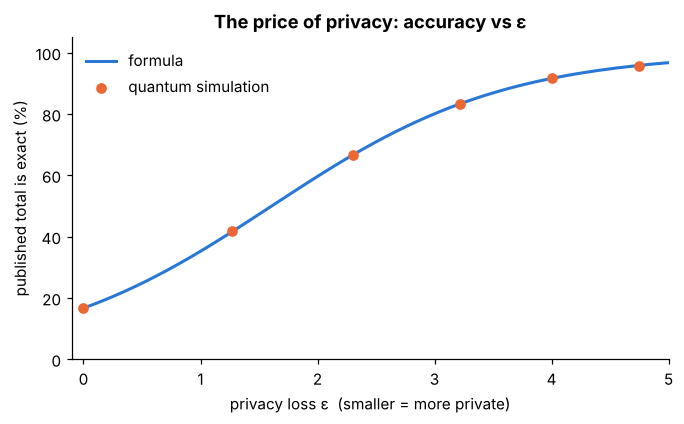

In [12]:
pp = np.linspace(0.01, 1, 200)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(np.log(1 + D * (1 - pp) / pp), 100 * (1 - pp + pp / D), color=BLUE, lw=2, label="formula")
ax.scatter(dp["ε from simulation"], dp["total correct (%)"], color=ORANGE, zorder=3, label="quantum simulation")
ax.set_xlabel("privacy loss ε  (smaller = more private)"); ax.set_ylabel("published total is exact (%)")
ax.set_xlim(-0.1, 5); ax.set_ylim(0, 105); ax.legend(frameon=False)
ax.set_title("The price of privacy: accuracy vs ε"); plt.show()

## Conclusions

1. **Quantum challenges are not automatically safer.** The naive quantum distance-bounding round can be relayed with
   probability $(2+\sqrt3)/4 \approx 0.933$, worse than the classical protocol's 3/4. The attack needs only one tilted
   qubit sent to the far-away prover. The exact SDP proves no quantum attack does better.
2. **One secret bit fixes it.** Replying $c \oplus k$ brings relay success down to 3/4, the same as classical, and keeps
   the quantum advantage against a dishonest prover (1/2 instead of 3/4 per round).
3. **Entanglement can replace private channels in MPC.** A shared GHZ state lets five voters publish only their total,
   checked exactly on the full quantum state. The catch moves elsewhere: the entanglement source must be trusted or tested.
4. **Noise can be a privacy feature.** Random phase errors on one qudit give a clean differential-privacy guarantee,
   with a precise trade-off between ε and accuracy.

**Try it yourself:** change the pre-ask angle, add a third basis to the protocol (edit `BASIS` and `protocol_matrix`),
use more voters (raise `N_VOTERS` and `D`), or change the noise model in Part B3.